In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
%load_ext autoreload
%autoreload 2

from fwh_analysis import FWHDataset, FWHPlotter

In [62]:
def p_element_plot(dataframe, title=None):
    norm = mcolors.LogNorm(vmin = 1e-3, vmax=1e-1)
    cmap = cm.coolwarm

    fig, ax = plt.subplots(figsize=[8,6])
    color_val = cmap(norm(dataframe['error']))
    ax.scatter(dataframe['elements'] / 1000, dataframe['P'], color=color_val)

    sm = plt.cm.ScalarMappable(cmap = cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label("Log Error (%)")

    ax.set_xlabel(f"Element Count $(10^3)$")
    # ax.set_xscale('log')
    ax.set_ylabel("Temporal Resolution, P (Points Per Period)")
    ax.set_title(title)

    plt.show()

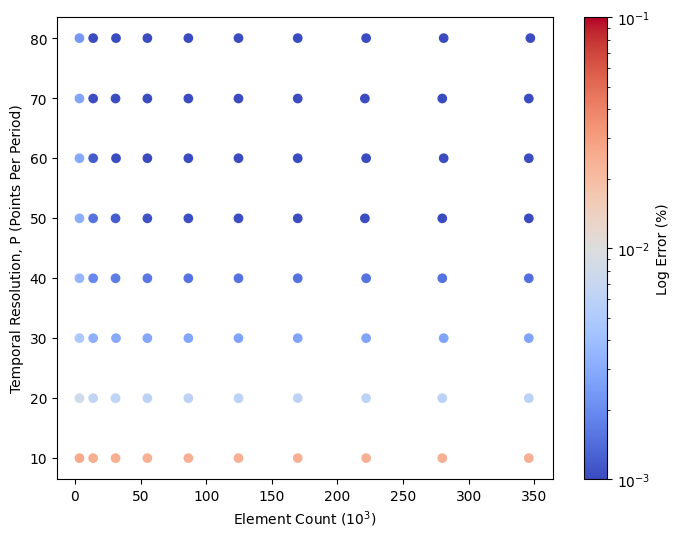

In [26]:
df_M09 = pd.DataFrame(FWHDataset.compile_fwh_batch('data_260603/test_M09', use_doppler=True))
p_element_plot(df_M09)

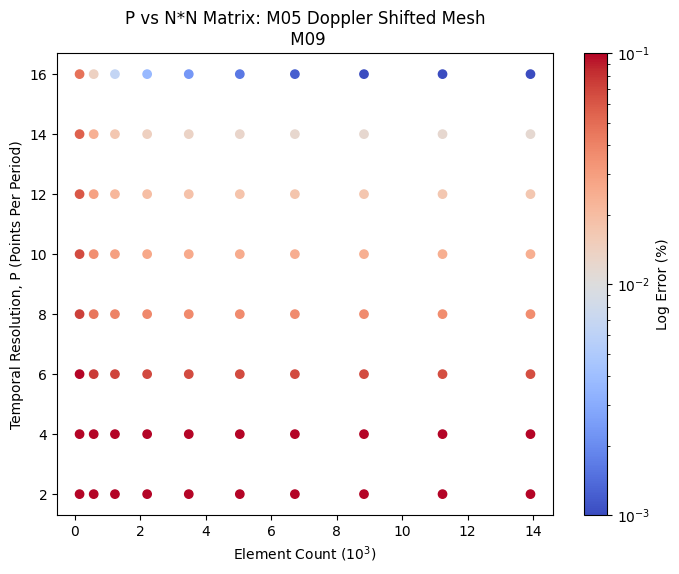

In [68]:
df_M0905 = pd.DataFrame(FWHDataset.compile_fwh_batch("data_260609/test_M09_M05_mesh"))
p_element_plot(df_M0905,
               title='P vs N*N Matrix: M05 Doppler Shifted Mesh\n M09')

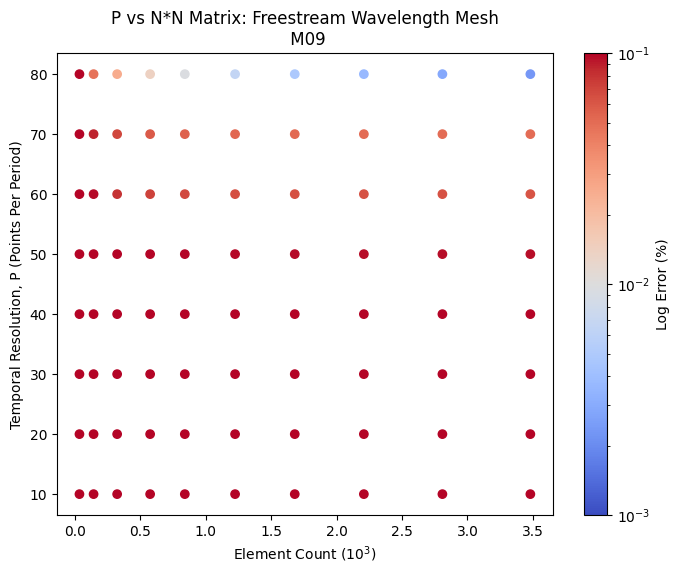

In [67]:
df_M09nd = pd.DataFrame(FWHDataset.compile_fwh_batch('data_260609/test_M09_non_doppler_mesh', use_doppler=False))
p_element_plot(df_M09nd, 
               title='P vs N*N Matrix: Freestream Wavelength Mesh\n M09')

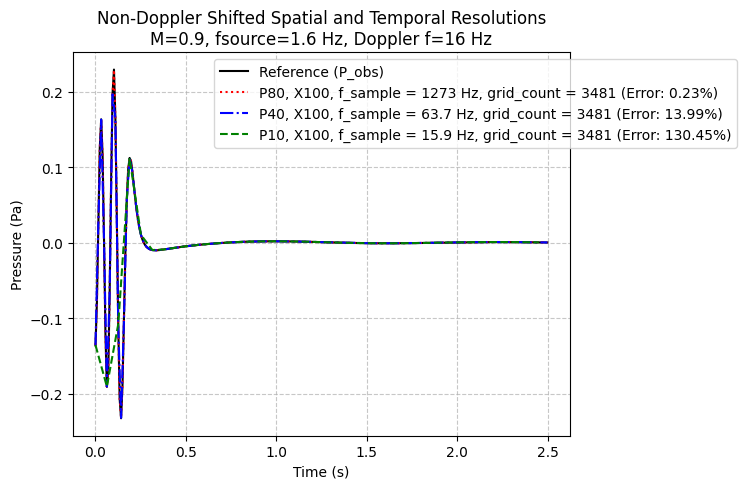

In [54]:
filepath = Path('data_260609/test_M09_non_doppler_mesh/')
ana = FWHDataset(filepath / 'ana_M90.dat')
p80_x100 = FWHDataset(filepath / 'P80_X100_M90.dat')
p40_x100 = FWHDataset(filepath / 'P40_X100_M90.dat')
p10_x100 = FWHDataset(filepath / 'P10_X100_M90.dat')

FWHPlotter.plot_pressure(ana, p80_x100, p40_x100, p10_x100, ref_col='P_obs', labels=[
    'P80, X100, f_sample = 1273 Hz, grid_count = 3481',
    'P40, X100, f_sample = 63.7 Hz, grid_count = 3481',
    'P10, X100, f_sample = 15.9 Hz, grid_count = 3481'
],
title="Non-Doppler Shifted Spatial and Temporal Resolutions\nM=0.9, fsource=1.6 Hz, Doppler f=16 Hz")

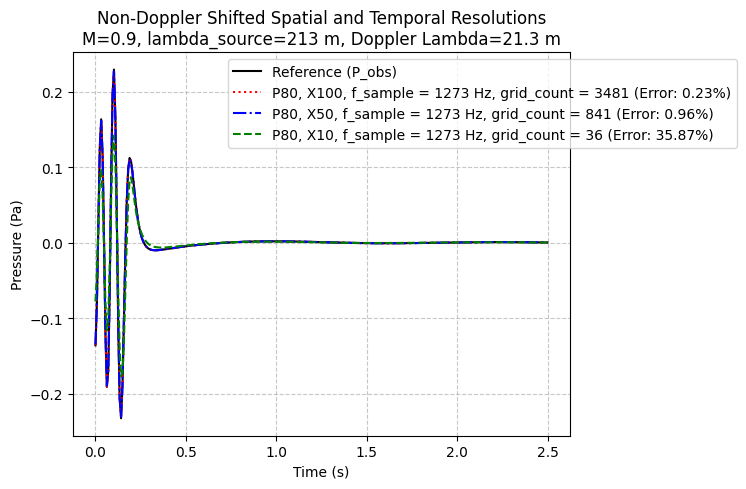

In [71]:
p80_x50 = FWHDataset(filepath / 'P80_X50_M90.dat')
p80_x10 = FWHDataset(filepath / 'P80_X10_M90.dat')

FWHPlotter.plot_pressure(ana, p80_x100, p80_x50, p80_x10, ref_col='P_obs', labels=[
    'P80, X100, f_sample = 1273 Hz, grid_count = 3481',
    'P80, X50, f_sample = 1273 Hz, grid_count = 841',
    'P80, X10, f_sample = 1273 Hz, grid_count = 36'
], title="Non-Doppler Shifted Spatial and Temporal Resolutions\n" \
"M=0.9, lambda_source=213 m, Doppler Lambda=21.3 m"
)